#Prophet - from Facebook

In [1]:
! pip install prophet #install Prophet

In [3]:
import pandas as pd

visitors = pd.read_csv("daily-website-visitors.csv", index_col = 'Row', thousands=",")

print('Data dimensions: ', visitors.shape) #2167 observations, 7 attributes
print('First observations')
print(visitors.head())
print()
print('Last observations')
print(visitors.tail())
visitors["Date"] = pd.to_datetime(visitors["Date"])
visitors["First.Time.Visits"] = pd.to_numeric(visitors["First.Time.Visits"], errors = 'coerce')
#keep only the data and the first time visitors
visitors = visitors[['Date', 'First.Time.Visits']]



Data dimensions:  (2167, 7)
First observations
           Day  Day.Of.Week       Date  Page.Loads  Unique.Visits  \
Row                                                                 
1       Sunday            1  9/14/2014        2146           1582   
2       Monday            2  9/15/2014        3621           2528   
3      Tuesday            3  9/16/2014        3698           2630   
4    Wednesday            4  9/17/2014        3667           2614   
5     Thursday            5  9/18/2014        3316           2366   

     First.Time.Visits  Returning.Visits  
Row                                       
1                 1430               152  
2                 2297               231  
3                 2352               278  
4                 2327               287  
5                 2130               236  

Last observations
            Day  Day.Of.Week       Date  Page.Loads  Unique.Visits  \
Row                                                                  
2163   Sa

In [4]:
#prophet requires that the time column is called ds, while the time series column needs to be called y. Let's rename them
visitors = visitors.rename(columns = {'Date': 'ds', 'First.Time.Visits': 'y'})

#keep only data from 01.01.2017
visitors = visitors[visitors['ds'] >= pd.to_datetime('2017-01-01')]
print('Data dimensions: ', visitors.shape)
print('First observations')
print(visitors.head())

Data dimensions:  (1327, 2)
First observations
            ds     y
Row                 
841 2017-01-01   832
842 2017-01-02  1448
843 2017-01-03  1970
844 2017-01-04  2226
845 2017-01-05  2058


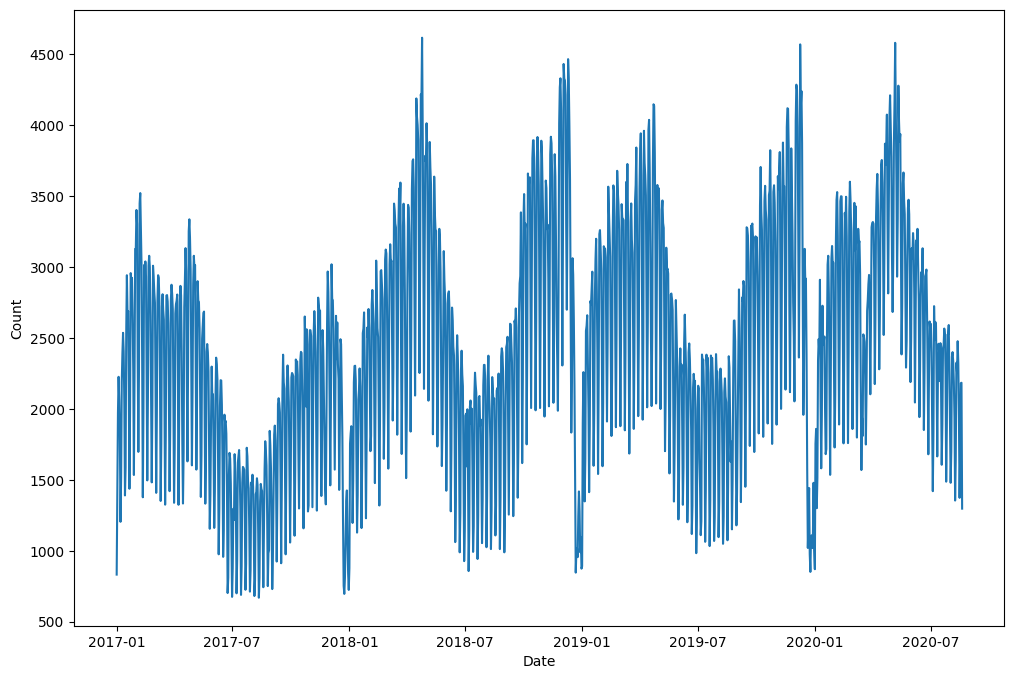

In [5]:
#Let's plot the data
import matplotlib.pyplot as plt

plt.figure(figsize = (12,8))
plt.plot(visitors['ds'], visitors['y'])
plt.xlabel("Date")
plt.ylabel("Count")
plt.show()

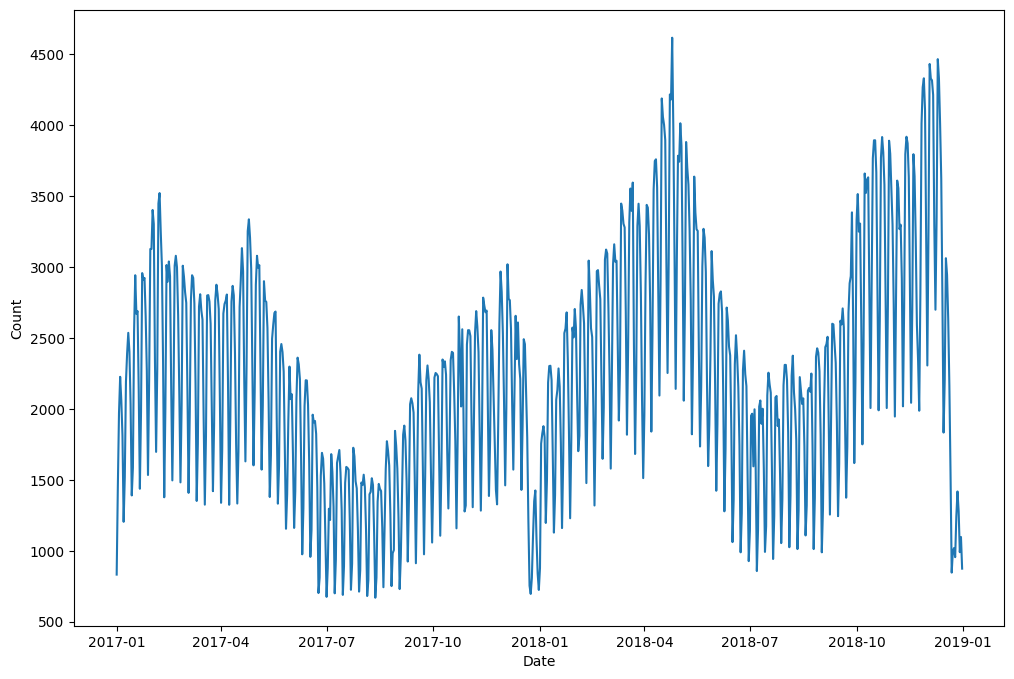

In [6]:
#Let's have a better look at the first 2 years
visitors_short = visitors[visitors['ds'] < pd.to_datetime('2019-01-01')]

plt.figure(figsize = (12,8))
plt.plot(visitors_short['ds'], visitors_short['y'])
plt.xlabel("Date")
plt.ylabel("Count")
plt.show()

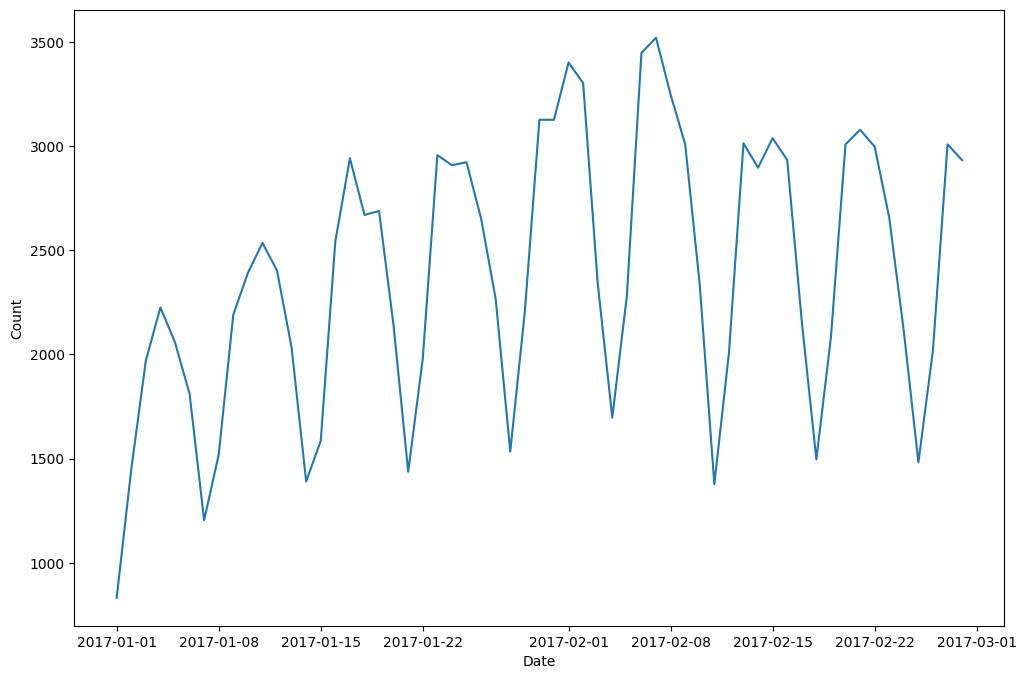

In [7]:
#Let's have a better look at the first 3 months
visitors_short2 = visitors[visitors['ds'] < pd.to_datetime('2017-03-01')]

plt.figure(figsize = (12,8))
plt.plot(visitors_short2['ds'], visitors_short2['y'])
plt.xlabel("Date")
plt.ylabel("Count")

plt.show()
#looks like we have a weekly seasonality as well

In [9]:
#let's do a train test - split. 85% of data for train, 15% for test
train_size = int(visitors.shape[0] * 0.85)
train = visitors.iloc[:train_size]
test = visitors.iloc[train_size:]
print('Train and test size: ', len(train), len(test))

Train and test size:  1127 200


In [10]:
#build the prophet model

from prophet import Prophet
from prophet.plot import add_changepoints_to_plot

model = Prophet()
model.add_country_holidays(country_name='US') #add the dummies for the holidays
#if you want to add your own holidays, you need to pass a dataframe to this function. It should have the following columns:
# holiday - (the name of the holiday)
# ds - data of the holiday
# lower_window - optional, it tells prophet how many days before the holiday to consider as part of the holiday
# upper_window - optional, it tells prophet how many days after the holiday to consider as part of the holiday

#train the model
model.fit(train)

#create time periods for the test data
future = model.make_future_dataframe(periods = len(test), freq = 'd')
print('Last observations of the future time periods: ')
print(future.tail())

#forecast for the future period
forecast = model.predict(future)

print('Last forecasted observations:')
print(forecast.tail())

print('Columns of the forecast result')
print(forecast.columns)


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


Last observations of the future time periods: 
             ds
1322 2020-08-15
1323 2020-08-16
1324 2020-08-17
1325 2020-08-18
1326 2020-08-19
Last forecasted observations:
             ds        trend   yhat_lower   yhat_upper  trend_lower  \
1322 2020-08-15  2525.461810   541.999315  1278.682672  2325.145479   
1323 2020-08-16  2525.383721   996.523049  1731.135167  2322.903529   
1324 2020-08-17  2525.305632  1912.205866  2662.072117  2321.403576   
1325 2020-08-18  2525.227543  1961.466586  2708.443142  2319.865216   
1326 2020-08-19  2525.149454  1949.803702  2677.652405  2318.171971   

      trend_upper  Christmas Day  Christmas Day_lower  Christmas Day_upper  \
1322  2705.953064            0.0                  0.0                  0.0   
1323  2707.092039            0.0                  0.0                  0.0   
1324  2708.188584            0.0                  0.0                  0.0   
1325  2709.489955            0.0                  0.0                  0.0   
1326  2710

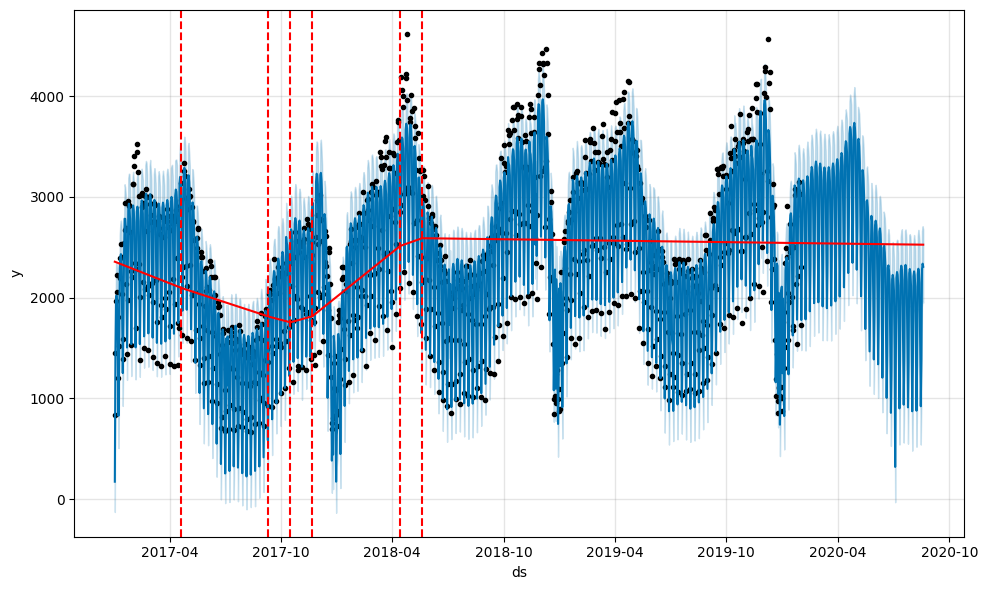

In [11]:
#plot the forecasts.
fig = model.plot(forecast)

#adds a trend line and the changepoints of the trend to the plot
a = add_changepoints_to_plot(fig.gca(), model, forecast)


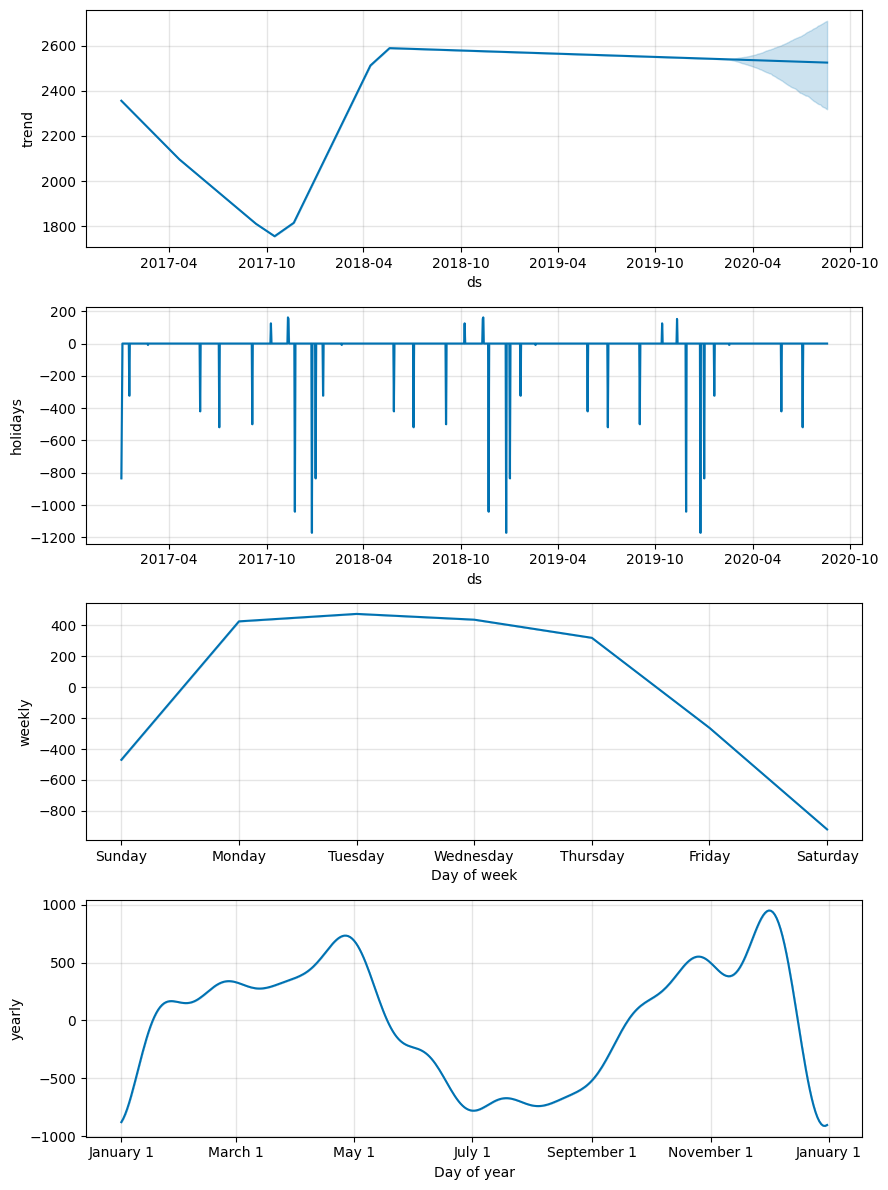

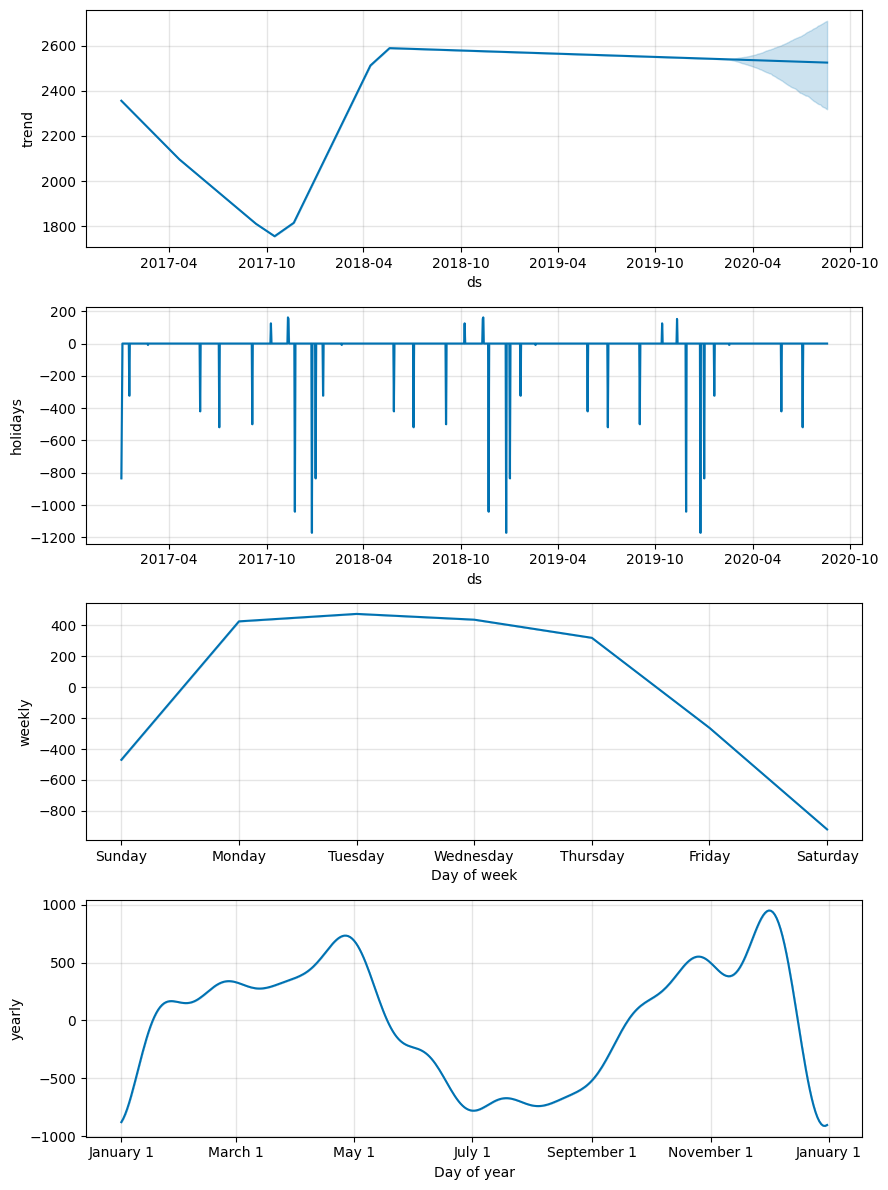

In [12]:
#plot the components of the forecast (trend, holiday effects, weekedly and yearly seasoality)
model.plot_components(forecast)

In [13]:
#let's evaluate the performance of the model, using MAPE, MAE and MSE
from sklearn import metrics
import numpy as np

#get the yhat column from the forecast output. Since we have a yhat for the entire period, but we want to evaluate only on the test data, we take values strating from the index equal to the size of the train data
prediction = forecast.loc[train_size:, 'yhat']

mape = metrics.mean_absolute_percentage_error(test['y'], prediction)
mae = metrics.mean_absolute_error(test['y'], prediction)
mse = metrics.mean_squared_error(test['y'], prediction)

print("Mape: ", mape)
print("Mae: ", mae)
print("Mse: ", mse)




Mape:  0.1567951980043183
Mae:  395.1214226011871
Mse:  236679.0756717949


In [15]:
from prophet.diagnostics import cross_validation
#do prophet's cross validation

model_cv = cross_validation(model,
initial='100 days', #the first training set if the the first 100 days
period='180 days', #how many observations to add for every new retrain: after the initial 100, you retrain at 280, then at 460, etc.
horizon = '365 days') #how many days to forecast for each trained data (so for first model we forecast observations 101 to 465)

print(model_cv)

INFO:prophet:Making 4 forecasts with cutoffs between 2017-08-10 00:00:00 and 2019-02-01 00:00:00


  0%|          | 0/4 [00:00<?, ?it/s]

             ds         yhat   yhat_lower   yhat_upper     y     cutoff
0    2017-08-11   917.132137   737.837060  1104.386388  1121 2017-08-10
1    2017-08-12   275.113248   102.084434   443.917372   669 2017-08-10
2    2017-08-13   650.769187   470.809941   831.135108   811 2017-08-10
3    2017-08-14  1476.423062  1297.998576  1645.460769  1346 2017-08-10
4    2017-08-15  1555.816957  1380.768984  1735.512975  1471 2017-08-10
...         ...          ...          ...          ...   ...        ...
1455 2020-01-28  3298.587482  2574.125650  4056.295402  3148 2019-02-01
1456 2020-01-29  3248.723217  2477.656722  4026.353185  3025 2019-02-01
1457 2020-01-30  3147.514891  2422.536470  3953.317868  3031 2019-02-01
1458 2020-01-31  2590.437414  1804.706265  3373.149095  2304 2019-02-01
1459 2020-02-01  1938.729354  1164.325090  2723.143763  1728 2019-02-01

[1460 rows x 6 columns]


In [17]:
from prophet.diagnostics import performance_metrics

#evaluate the cross-validation performance.
model_perf = performance_metrics(model_cv)

print("Performance evaluation dimensions: ", model_perf.shape)

print(model_perf)
#performance is returned for every forecast horizon separately.
#However, prophet can drop a few horizons, if it does not have enough data for forecasting, or it feels the forecasts are not stable.


Performance evaluation dimensions:  (329, 8)
     horizon            mse        rmse         mae      mape     mdape  \
0    37 days  124451.076074  352.776241  269.192449  0.147454  0.103659   
1    38 days  129249.369882  359.512684  272.803534  0.146399  0.102129   
2    39 days  131170.110456  362.174144  274.598584  0.145794  0.099614   
3    40 days  137540.045378  370.863918  282.992402  0.148308  0.103659   
4    41 days  144352.604660  379.937633  290.102523  0.150248  0.105261   
..       ...            ...         ...         ...       ...       ...   
324 361 days  375718.673306  612.958949  544.691938  0.317029  0.284267   
325 362 days  362876.792816  602.392557  536.719874  0.306695  0.280293   
326 363 days  355257.808244  596.035073  532.003098  0.298907  0.275021   
327 364 days  350928.118880  592.391863  529.004395  0.291543  0.269051   
328 365 days  346394.229109  588.552656  525.573525  0.284151  0.260194   

        smape  coverage  
0    0.176678  0.523973  
1 

Neural network example.
Consider the sunspots time series (it is actually part of the statsmodels.datasets package, so we do not need to upload csv files).

In [25]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.datasets import sunspots

data = sunspots.load_pandas().data
#transform year to datetime
data['YEAR'] = pd.to_datetime(data['YEAR'], format='%Y')

#rename SUNACTIVITY column to value
data = data.rename(columns={'SUNACTIVITY': 'value'})

print('Data dimensions: ' ,data.shape)
print('First observations: ')
print(data.head())

Data dimensions:  (309, 2)
First observations: 
        YEAR  value
0 1700-01-01    5.0
1 1701-01-01   11.0
2 1702-01-01   16.0
3 1703-01-01   23.0
4 1704-01-01   36.0


In [44]:

#let's do a sqrt transformation - to make sure that values will be positive
data['sqrt_value'] = np.sqrt(data['value'])

#auxiliary function to create a set of lags for a model
#for every observation, it returns a list with the previous lags observations - so that we have separately the train data (in X) and the corresponding result (in y)
def make_lags(series, lags):
    X, y = [], []
    for i in range(lags, len(series)):
        X.append(series[i-lags:i])
        y.append(series[i])
    return np.array(X), np.array(y)

lags = 25 #you can experiment with how the result changes, if you change the nr of lags.
series = data['sqrt_value'].values
X, y = make_lags(series, lags)



In [45]:
#fit the ANN model

from sklearn.neural_network import MLPRegressor

model = MLPRegressor(
    hidden_layer_sizes=(10,), #how many nodes to have on the hidden layer
    activation='relu', #activation function
    solver='adam',
    random_state=42, #random value, we set it to make the experiments repeatable
    max_iter=2000
)

model.fit(X, y)

MLPRegressor(hidden_layer_sizes=(10,), max_iter=2000, random_state=42)

In [46]:
h = 30 #forecast horizon

history = series.tolist() #these are the sqrt values from the data

forecast = [] #this is where we will store the forecast values

for _ in range(h):
    x_input = np.array(history[-lags:]).reshape(1, -1) #take the last lags values from the history (and reshape it to a shape needed by the model)
    yhat = model.predict(x_input)[0] # use the previous values as input for the model and get a forecast (yhat)
    forecast.append(yhat) #add the forecast to the forecasts
    history.append(yhat) #add the forecast to the history, so that at the next iteration this will also be considered

#undo the square root
forecast = np.square(forecast)

#build future time steps to go with the forecasts (now forecasts is just a vector of values, no time information is connected to them)
last_year = data['YEAR'].iloc[-1]

future_index = [last_year + pd.DateOffset(years=i) for i in range(1, h+1)]

#combine the timestamps with the forecasts
forecast_series = pd.Series(forecast, index=future_index)



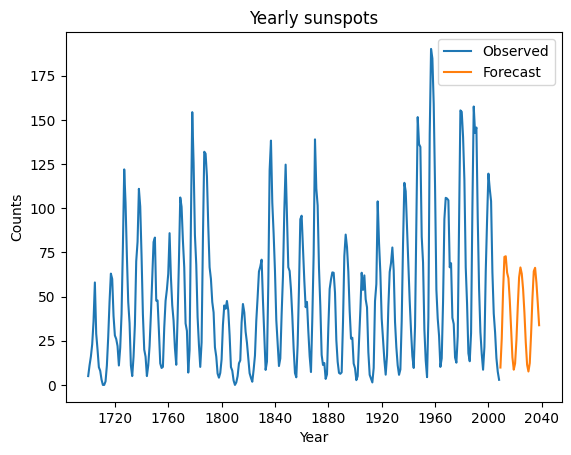

In [47]:
#plot the results
plt.figure()
plt.plot(data['YEAR'], data['value'], label='Observed')
plt.plot(forecast_series.index, forecast_series, label='Forecast')
plt.xlabel("Year")
plt.ylabel("Counts")
plt.title("Yearly sunspots")
plt.legend()
plt.show()

